# Aprendizaje de Máquina: Proyecto

Arantxa Valencia Reyes - 0265784

Ana Luisa Villeda Anleu - 0266043

## Clasificación del Estado de Madurez del Aguacate

El objetivo principal de este proyecto es desarrollar, evaluar y comparar modelos de clasificación de Machine Learning para predecir el tipo de personalidad de una persona (MBTI) a partir de sus respuestas al cuestionario de evaluación psicológica.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, accuracy_score)
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid", context="notebook")
UP_BLUE, UP_RED, UP_GOLD = "#003366", "#BA0C2F", "#C69214"

---

# Análisis Exploratorio - EDA

El análisis exploratorio nos permitió revisar las dimensiones del conjunto de datos, los tipos de variables, los estadísticos descriptivos, la distribución de la variable objetivo y las relaciones entre variables. En esta etapa buscabamos identificar problemas de calidad y comprender la estructura de los datos antes de entrenar los modelos.

In [2]:
df = pd.read_csv("./16P.csv", encoding='cp1252')



Primero se muestra que hay 59,999 registros y 62 columnas antes de la limpieza. Cada registro contiene un identificador y respuestas a las preguntas del cuestionario, además de la categoría de personalidad. La vista inicial nos permite comprobar que las respuestas están representadas numéricamente, tal como están en el cuestionario. También, a simple vista se ve que las respuestas van de -3 a 3

In [3]:
print(df.shape)
df.head()

(59999, 62)


,Response Id,You regularly make new friends.,You spend a lot of your free time exploring various random topics that pique your interest,Seeing other people cry can easily make you feel like you want to cry too,You often make a backup plan for a backup plan.,"You usually stay calm, even under a lot of pressure","At social events, you rarely try to introduce yourself to new people and mostly talk to the ones you already know",You prefer to completely finish one project before starting another.,You are very sentimental.,You like to use organizing tools like schedules and lists.,...,You believe that pondering abstract philosophical questions is a waste of time.,"You feel more drawn to places with busy, bustling atmospheres than quiet, intimate places.",You know at first glance how someone is feeling.,You often feel overwhelmed.,You complete things methodically without skipping over any steps.,You are very intrigued by things labeled as controversial.,You would pass along a good opportunity if you thought someone else needed it more.,You struggle with deadlines.,You feel confident that things will work out for you.,Personality
0,0,0,0,0,0,0,1,1,0,0,...,0,0,0,-1,0,0,0,0,0,ENFP
1,1,0,0,-2,-3,-1,2,-2,0,3,...,0,-2,0,2,0,-1,-1,-1,3,ISFP
2,2,0,0,2,0,-1,2,0,0,1,...,0,2,0,2,-1,0,1,2,1,INFJ
3,3,0,-1,3,-1,0,0,-2,0,-2,...,0,0,-1,-1,0,1,0,-2,-1,ISTP
4,4,0,0,-1,0,2,-1,-2,0,1,...,0,1,0,2,0,1,-1,2,-1,ENFJ


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59999 entries, 0 to 59998
Data columns (total 62 columns):
 #   Column                                                                                                                Non-Null Count  Dtype 
---  ------                                                                                                                --------------  ----- 
 0   Response Id                                                                                                           59999 non-null  int64 
 1   You regularly make new friends.                                                                                       59999 non-null  int64 
 2   You spend a lot of your free time exploring various random topics that pique your interest                            59999 non-null  int64 
 3   Seeing other people cry can easily make you feel like you want to cry too                                             59999 non-null  int64 
 4   You often 

Los estadísticos descriptivos resumen la media, desviación estandar y rango de las variables numéricas. Aquí podemos ver que las preguntas del cuestionario en efecto van en un rango de -3 a 3, sus resultados están al rededor de cero y tienen una media bastante cercana a cero.

In [5]:
display(df.describe().T[['mean', 'std', 'min', '50%', 'max']])

,mean,std,min,50%,max
Response Id,29999.000000,17320.363738,0.0,29999.0,59998.0
You regularly make new friends.,-0.000867,0.365701,-2.0,0.0,1.0
You spend a lot of your free time exploring various random topics that pique your interest,-0.000467,0.364652,-1.0,0.0,1.0
Seeing other people cry can easily make you feel like you want to cry too,0.000267,1.527343,-3.0,0.0,3.0
You often make a backup plan for a backup plan.,-0.232887,1.502173,-3.0,0.0,3.0
...,...,...,...,...,...
You complete things methodically without skipping over any steps.,-0.000533,0.364606,-1.0,0.0,1.0
You are very intrigued by things labeled as controversial.,0.000667,0.368426,-2.0,0.0,1.0
You would pass along a good opportunity if you thought someone else needed it more.,0.125152,1.515761,-3.0,0.0,3.0
You struggle with deadlines.,0.001983,1.524584,-3.0,0.0,3.0


## Limpieza de datos

Se eliminaron registros duplicados y filas con valores faltantes. Después de esta operación, el conjunto conservó 59,999 filas, es decir que no hubo una reducción en el número de registros. Esto nos dice que el dataset esta limpio

In [6]:
#Quitar duplicados y NaN
df = df.drop_duplicates()
df = df.dropna()
print(df.shape)

(59999, 62)


## Distribución de las clases

Las 16 categorías mostraron cantidades muy similares, aproximadamente entre 3,734 y 3,769 observaciones por clase. Por tanto, la variable objetivo está bastante balanceada y no se ve un desbalance marcado que favorezca a una sola personalidad. Este equilibrio facilitaba la comparación de accuracy entre modelos.

In [7]:
print(df["Personality"].value_counts())

Personality
ESFP    3769
INFJ    3761
ENFP    3760
ENTP    3760
ESTJ    3759
ISTJ    3756
ISTP    3755
ESTP    3749
ISFP    3746
ESFJ    3746
ENFJ    3743
INTJ    3743
INTP    3742
ISFJ    3739
ENTJ    3737
INFP    3734
Name: count, dtype: int64


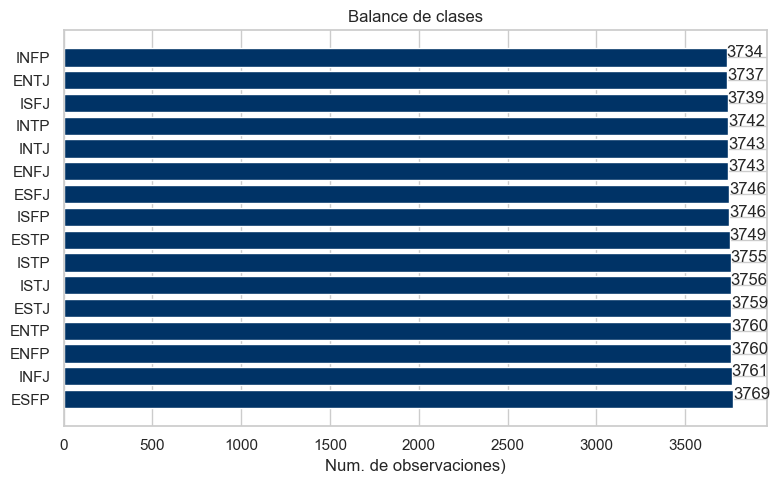

In [8]:
conteo = df["Personality"].value_counts()  

plt.figure(figsize=(8, 5))
plt.barh(conteo.index.astype(str), conteo.values, color=UP_BLUE)

for x,y in enumerate(conteo.values):
    plt.text(y,x,f"{y}")


plt.xlabel("Num. de observaciones)")
plt.title("Balance de clases")
plt.tight_layout()
plt.show()

La desviación estándar nos ayuda a saber qué tanto varían las respuestas de las personas dentro de cada tipo de personalidad. Esto nos permite observar si existen diferencias en las respuestas entre los tipos de personalidad.

In [9]:
#Desvaición estándar de cada variable con la objetivo
df.groupby("Personality").std()

,Response Id,You regularly make new friends.,You spend a lot of your free time exploring various random topics that pique your interest,Seeing other people cry can easily make you feel like you want to cry too,You often make a backup plan for a backup plan.,"You usually stay calm, even under a lot of pressure","At social events, you rarely try to introduce yourself to new people and mostly talk to the ones you already know",You prefer to completely finish one project before starting another.,You are very sentimental.,You like to use organizing tools like schedules and lists.,...,You would love a job that requires you to work alone most of the time.,You believe that pondering abstract philosophical questions is a waste of time.,"You feel more drawn to places with busy, bustling atmospheres than quiet, intimate places.",You know at first glance how someone is feeling.,You often feel overwhelmed.,You complete things methodically without skipping over any steps.,You are very intrigued by things labeled as controversial.,You would pass along a good opportunity if you thought someone else needed it more.,You struggle with deadlines.,You feel confident that things will work out for you.
Personality,,,,,,,,,,,,,,,,,,,,,
ENFJ,17232.456072,0.371995,0.380209,1.523541,1.210218,1.570666,1.229426,1.185494,0.372327,1.503959,...,0.360378,0.374538,1.139058,0.369175,1.098831,0.373131,0.372407,1.509869,1.500438,1.549036
ENFP,17356.750224,0.369414,0.352441,1.233254,1.174339,1.528641,1.511052,1.537818,0.371879,1.195003,...,0.371930,0.364571,1.532577,0.368997,1.226670,0.375070,0.369912,1.091449,1.224151,1.590397
ENTJ,17504.867057,0.366885,0.359883,1.218996,1.150583,1.090765,1.205332,1.573695,0.352396,1.554760,...,0.368265,0.369105,1.561746,0.362874,1.514520,0.367944,0.373433,1.511303,1.426282,1.228613
ENTP,17327.338133,0.362516,0.364701,1.206962,1.195537,1.089242,1.206752,1.122598,0.372889,1.536629,...,0.372642,0.367220,1.248479,0.371903,1.480200,0.363400,0.361406,1.177141,1.205546,1.159072
ESFJ,17337.869631,0.370397,0.366272,1.550216,1.521433,1.126570,1.551472,1.271184,0.366832,1.573731,...,0.368644,0.367919,1.105021,0.358751,1.227517,0.359853,0.364646,1.228332,1.552416,1.505197
ESFP,17263.501542,0.353914,0.377445,1.177707,1.541706,1.146448,1.507526,1.538604,0.367762,1.557081,...,0.363088,0.362814,1.508880,0.369294,1.202426,0.380299,0.357879,1.609479,1.494254,1.226301
ESTJ,17562.776245,0.353987,0.362189,1.142787,1.292965,1.513007,1.156291,1.190732,0.374833,1.199012,...,0.355143,0.381168,1.553882,0.369111,1.225590,0.353269,0.358876,1.573834,1.148547,1.601580
ESTP,17297.543264,0.366698,0.362302,1.524623,1.210473,1.294619,1.491781,1.510267,0.362679,1.528168,...,0.370324,0.359618,1.184661,0.361134,1.174658,0.366617,0.372832,1.573762,1.566635,1.551079
INFJ,17332.045118,0.367011,0.371423,1.229358,1.253207,1.132786,1.224541,1.519271,0.376137,1.241903,...,0.366819,0.359784,1.538641,0.378266,1.180870,0.357662,0.375081,1.130245,1.558172,1.537408


## Matriz de correlación

La matriz resume las correlaciones lineales entre las variables numéricas y la codificación numérica de la personalidad. El identificador Response Id se excluye de esta visualización para evitar tratarlo como una característica sustantiva. En general, la matriz nos sirvió como exploración inicial, ya que nos ayudó a ver que no hay una correlación fuerte entre ninguna de las variables, lo que no sugiere que el resultado de personalidad toma información de todas las preguntas del test

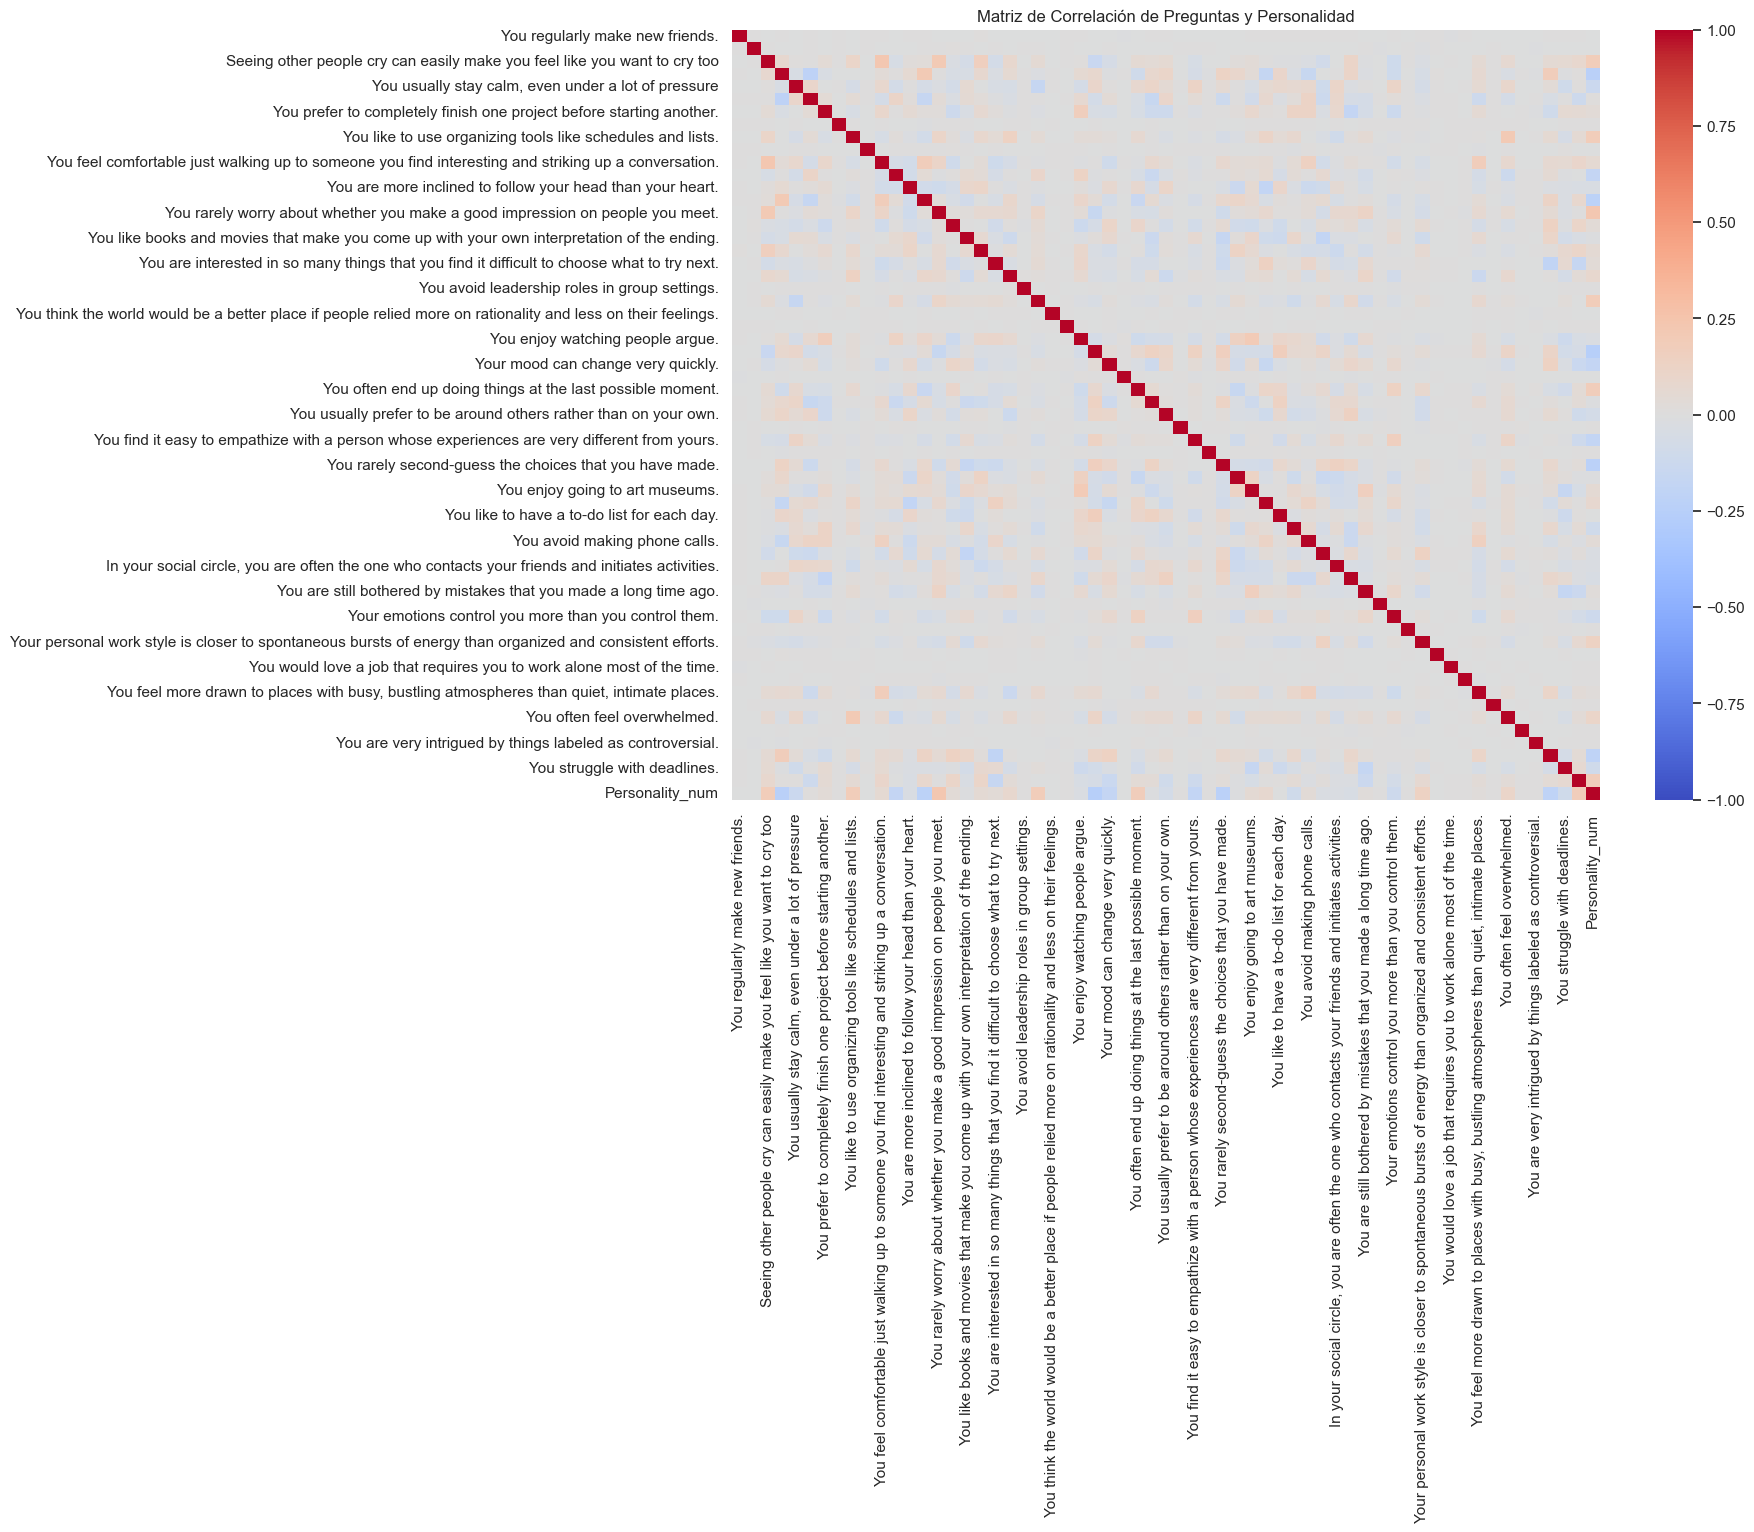

In [10]:
personality_map = {
    'ENFJ': 0, 'ENFP': 1, 'ENTJ': 2, 'ENTP': 3,
    'ESFJ': 4, 'ESFP': 5, 'ESTJ': 6, 'ESTP': 7,
    'INFJ': 8, 'INFP': 9, 'INTJ': 10, 'INTP': 11,
    'ISFJ': 12, 'ISFP': 13, 'ISTJ': 14, 'ISTP': 15
}

df_corr = df.copy()
df_corr['Personality_num'] = df_corr['Personality'].map(personality_map)

if 'Response Id' in df_corr.columns:
    df_corr = df_corr.drop(columns=['Response Id'])

plt.figure(figsize=(14, 10))
sns.heatmap(
    df_corr.select_dtypes(include='number').corr(),
    annot=False,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)
plt.title('Matriz de Correlación de Preguntas y Personalidad')
plt.show()

---

# MATRIZ DE DISEÑO

Se separan las variables predictoras (X) de la variable objetivo (y) y se divide el conjunto en entrenamiento y prueba, reservando el 30 % para la evaluación final. El uso de stratify=y mantiene más o menos la proporción de las 16 clases en ambas particiones, mientras que random_state=42 hace reproducible la división.

También estandarizamos las variables usando los parámetros aprendidos únicamente a partir del conjunto de entrenamiento. Esta transformación es principalmente para para LDA y KNN, ya que sus resultados pueden verse afectados por la escala de las características.

In [10]:

X = df.drop(columns=["Personality"])
y = df["Personality"]

X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.30,random_state=42,stratify=y
)

scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

---

# LDA o QDA


LDA busca separar las clases mediante combinaciones lineales de las características, bajo supuestos estadísticos sobre la distribución de los datos y la estructura de covarianza de los grupos. Se evalúa con el conjunto de prueba y se complementa el accuracy con precision, recall, F1-score y una matriz de confusión.

Resultado observado: el modelo obtiene un accuracy de aproximadamente 90.56 %. Es un resultado alto en este conjunto, aunque las métricas por clase permiten observar diferencias: algunas categorías se clasifican mejor que otras. Por ejemplo, ESFJ e INTJ presentan resultados inferiores a los de varias clases con F1-score cercano o superior a 0.90.

In [11]:
LDA_model = LinearDiscriminantAnalysis()
LDA_model.fit(X_train_s, y_train)
y_pred_lda = LDA_model.predict(X_test_s)
acc_lda = accuracy_score(y_test, y_pred_lda)

=== RESULTADOS LDA ===
Accuracy en Test: 0.9056111111111111
              precision    recall  f1-score   support

        ENFJ       0.91      0.91      0.91      1123
        ENFP       0.92      0.93      0.92      1128
        ENTJ       0.94      0.94      0.94      1121
        ENTP       0.94      0.94      0.94      1128
        ESFJ       0.85      0.82      0.84      1124
        ESFP       0.94      0.95      0.95      1131
        ESTJ       0.93      0.94      0.94      1128
        ESTP       0.92      0.94      0.93      1125
        INFJ       0.93      0.89      0.91      1128
        INFP       0.90      0.90      0.90      1120
        INTJ       0.85      0.89      0.87      1123
        INTP       0.88      0.91      0.89      1122
        ISFJ       0.88      0.85      0.87      1122
        ISFP       0.92      0.88      0.90      1124
        ISTJ       0.90      0.89      0.90      1127
        ISTP       0.87      0.90      0.89      1126

    accuracy        

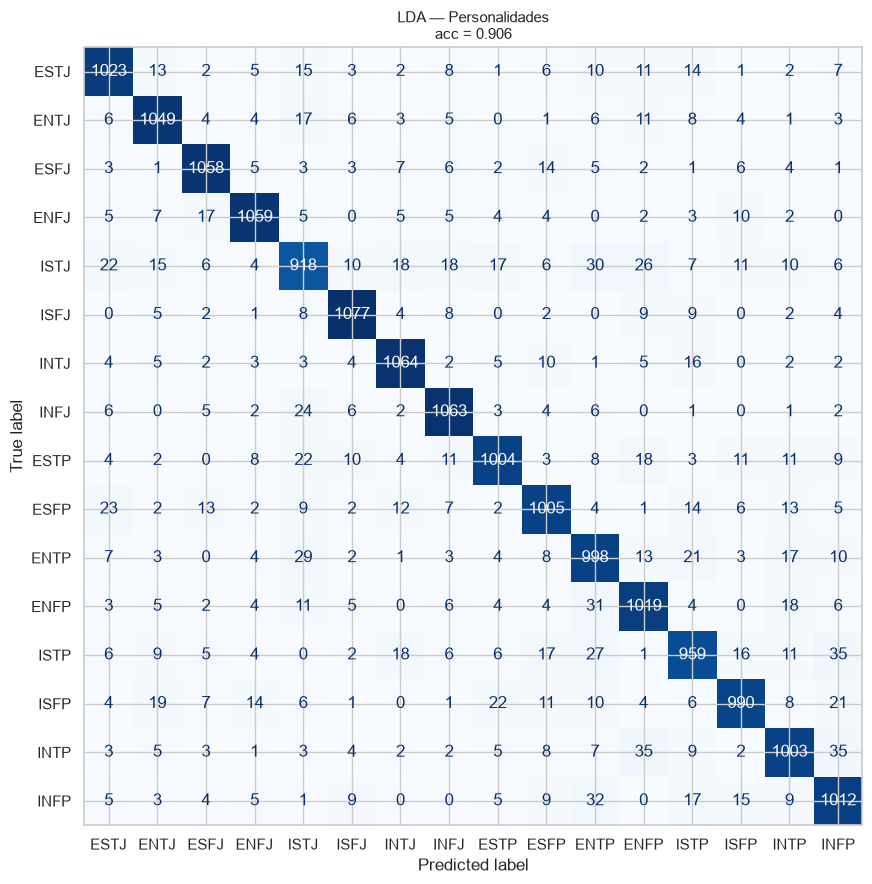

In [12]:
class_names = ['ESTJ', 'ENTJ','ESFJ','ENFJ','ISTJ','ISFJ','INTJ',
               'INFJ','ESTP','ESFP','ENTP','ENFP','ISTP','ISFP',
               'INTP','INFP']

print(f"=== RESULTADOS LDA ===")
print(f"Accuracy en Test: {acc_lda}")
print(classification_report(y_test, y_pred_lda))

# Matriz de Confusión estilo Lab
fig, ax = plt.subplots(figsize=(13, 9))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lda, 
    display_labels=class_names, 
    cmap="Blues", 
    values_format="d", 
    ax=ax, 
    colorbar=False
)
ax.set_title(f"LDA — Personalidades\nacc = {acc_lda:.3f}", fontsize=11)
plt.tight_layout()
plt.show()

---

# KNN

KNN clasifica cada observación a partir de las clases de sus vecinos más cercanos en el espacio de características. El parámetro K controla cuántos vecinos intervienen en la decisión: valores pequeños producen fronteras más sensibles a observaciones individuales, mientras que valores mayores suavizan la decisión.

La gráfica compara el accuracy promedio de validación cruzada para distintos valores de K. En esta ejecución, el valor seleccionado es K = 1. Un valor tan pequeño puede capturar patrones locales muy específicos; por ello, conviene considerar el riesgo de sensibilidad al ruido y revisar que el procedimiento de validación use el mismo preprocesamiento que el entrenamiento final.

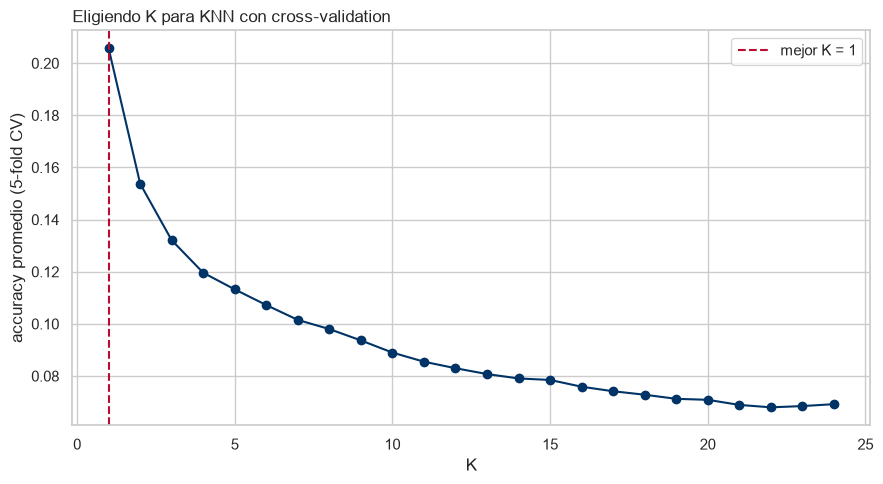

In [13]:
k_grid = range(1, 25)
cv_scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5).mean() for k in k_grid]
best_k = list(k_grid)[int(np.argmax(cv_scores))]

plt.figure(figsize=(9, 5))
plt.plot(list(k_grid), cv_scores, marker="o", color=UP_BLUE)
plt.axvline(best_k, color=UP_RED, ls="--", label=f"mejor K = {best_k}")
plt.xlabel("K")
plt.ylabel("accuracy promedio (5-fold CV)")
plt.title("Eligiendo K para KNN con cross-validation", loc="left")
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
KNN_model = KNeighborsClassifier(n_neighbors=best_k)
KNN_model.fit(X_train_s, y_train)
y_pred_knn = KNN_model.predict(X_test_s)
acc_knn = accuracy_score(y_test, y_pred_knn)

=== RESULTADOS KNN (K=1) ===
Accuracy en Test: 0.9555555555555556
Reporte de Clasificación:
              precision    recall  f1-score   support

        ENFJ       0.95      0.97      0.96      1123
        ENFP       0.97      0.97      0.97      1128
        ENTJ       0.96      0.95      0.96      1121
        ENTP       0.96      0.97      0.96      1128
        ESFJ       0.95      0.95      0.95      1124
        ESFP       0.96      0.97      0.96      1131
        ESTJ       0.97      0.96      0.97      1128
        ESTP       0.95      0.98      0.96      1125
        INFJ       0.96      0.94      0.95      1128
        INFP       0.96      0.95      0.96      1120
        INTJ       0.95      0.95      0.95      1123
        INTP       0.94      0.94      0.94      1122
        ISFJ       0.96      0.95      0.96      1122
        ISFP       0.96      0.93      0.95      1124
        ISTJ       0.94      0.94      0.94      1127
        ISTP       0.95      0.96      0.96

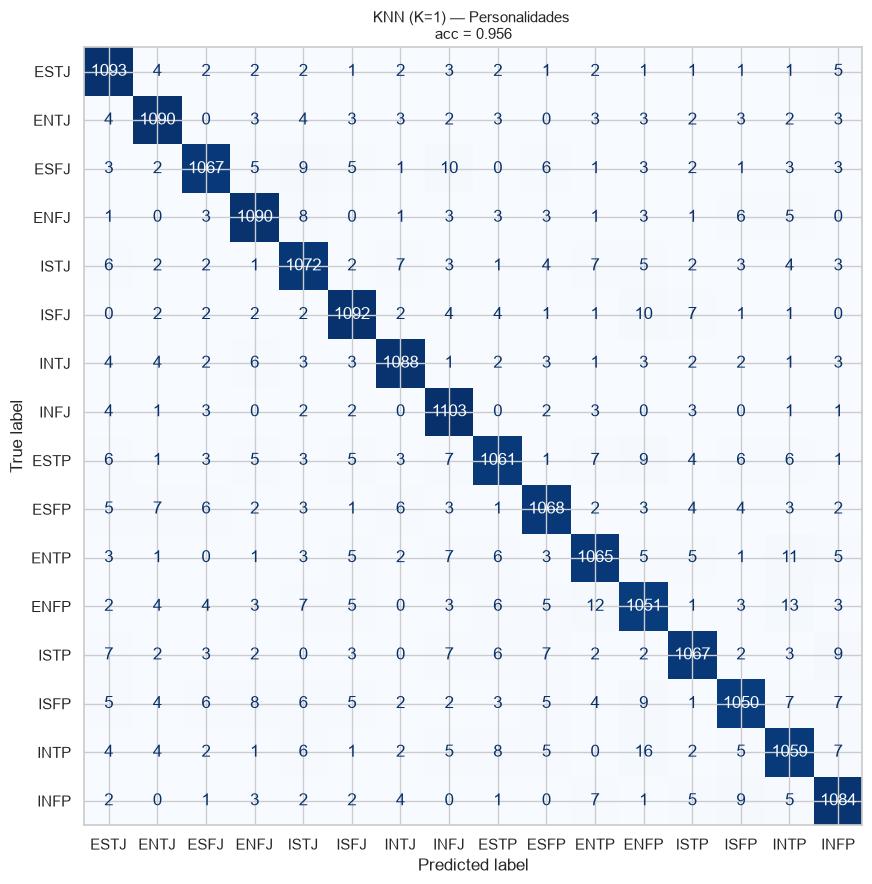

In [15]:
print(f"=== RESULTADOS KNN (K={best_k}) ===")
print(f"Accuracy en Test: {acc_knn}")

print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred_knn))

# 5. Matriz de Confusión estilo Lab
fig, ax = plt.subplots(figsize=(13, 9))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_knn, 
    display_labels=class_names, 
    cmap="Blues", 
    values_format="d", 
    ax=ax, 
    colorbar=False
)
ax.set_title(f"KNN (K={best_k}) — Personalidades \nacc = {acc_knn:.3f}", fontsize=11)
plt.tight_layout()
plt.show()

---

# Árbol

Un árbol de decisión aprende reglas de separación sobre las características. Puede representar relaciones no lineales y es relativamente fácil de interpretar, pero un árbol demasiado profundo puede ajustarse en exceso a los datos de entrenamiento.

La poda por complejidad de costo compara valores de ccp_alpha mediante validación cruzada para buscar un equilibrio entre complejidad y rendimiento. En esta ejecución, el valor seleccionado es alpha = 0.0001. La comparación posterior permite revisar el número de hojas y el accuracy en prueba de los árboles podado y sin podar.

In [16]:
arbol_completo = DecisionTreeClassifier(random_state=42)
path = arbol_completo.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas[:-1]

cv_acc = []
for alpha in ccp_alphas:
    tree = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    scores = cross_val_score(tree, X_train, y_train, cv=5, scoring="accuracy")
    cv_acc.append(scores.mean())

best_alpha = ccp_alphas[int(np.argmax(cv_acc))]
print(f"Mejor alpha por CV: {best_alpha:.4f}")


Mejor alpha por CV: 0.0001


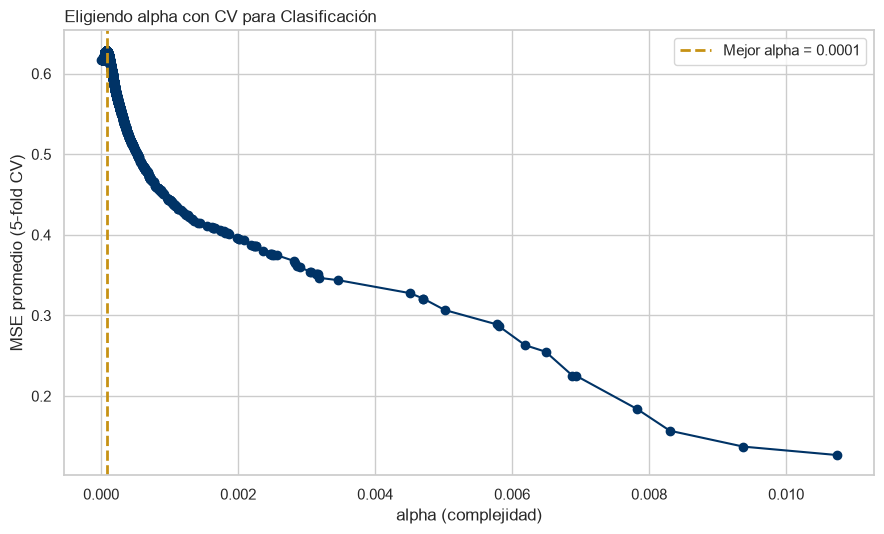

In [17]:
plt.figure(figsize=(9, 5.5))
plt.plot(ccp_alphas, cv_acc, marker="o", color=UP_BLUE)
plt.axvline(best_alpha, color=UP_GOLD, ls="--", lw=2, label=f"Mejor alpha = {best_alpha:.4f}")
plt.xlabel("alpha (complejidad)")
plt.ylabel("MSE promedio (5-fold CV)")
plt.title("Eligiendo alpha con CV para Clasificación", loc="left")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
arbol_podado = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha)
arbol_podado.fit(X_train, y_train)
arbol_sin_podar = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

y_pred_ap = arbol_podado.predict(X_test)
acc_ap = accuracy_score(y_test, y_pred_ap)

y_pred_sp = arbol_sin_podar.predict(X_test)
acc_sp = accuracy_score(y_test, y_pred_sp)


In [19]:

comparacion = pd.DataFrame({
    "modelo": ["Sin podar", "Podado (CV)"],
    "n_hojas": [arbol_sin_podar.get_n_leaves(), arbol_podado.get_n_leaves()],
    "accuracy_test": [
        accuracy_score(y_test, arbol_sin_podar.predict(X_test)),
        accuracy_score(y_test, arbol_podado.predict(X_test)),
    ],
}).round(3)
comparacion

,modelo,n_hojas,accuracy_test
0,Sin podar,9585,0.636
1,Podado (CV),2393,0.646


La tabla muestra que el árbol sin podar tiene 9,585 hojas y un accuracy de prueba de 0.636, mientras que el árbol podado tiene 2,393 hojas y un accuracy de 0.646. En estos resultados, la poda reduce considerablemente la complejidad y mejora ligeramente el desempeño en prueba.

Esto es consistente con la idea de que una estructura más sencilla puede generalizar mejor. Aun así, la diferencia de accuracy es pequeña, y la elección final también puede considerar interpretabilidad y estabilidad.

In [20]:
print("=== RESULTADOS ÁRBOL DE DECISIÓN (PODADO) ===")
print(f"Accuracy en Test: {acc_ap:.4f}\n")
print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred_sp, target_names=class_names, zero_division=0))

=== RESULTADOS ÁRBOL DE DECISIÓN (PODADO) ===
Accuracy en Test: 0.6457

Reporte de Clasificación:
              precision    recall  f1-score   support

        ESTJ       0.65      0.65      0.65      1123
        ENTJ       0.64      0.61      0.63      1128
        ESFJ       0.68      0.69      0.68      1121
        ENFJ       0.65      0.65      0.65      1128
        ISTJ       0.60      0.59      0.60      1124
        ISFJ       0.64      0.65      0.65      1131
        INTJ       0.66      0.66      0.66      1128
        INFJ       0.66      0.69      0.68      1125
        ESTP       0.63      0.62      0.62      1128
        ESFP       0.64      0.61      0.62      1120
        ENTP       0.60      0.63      0.61      1123
        ENFP       0.62      0.62      0.62      1122
        ISTP       0.62      0.64      0.63      1122
        ISFP       0.62      0.63      0.63      1124
        INTP       0.62      0.62      0.62      1127
        INFP       0.64      0.63    

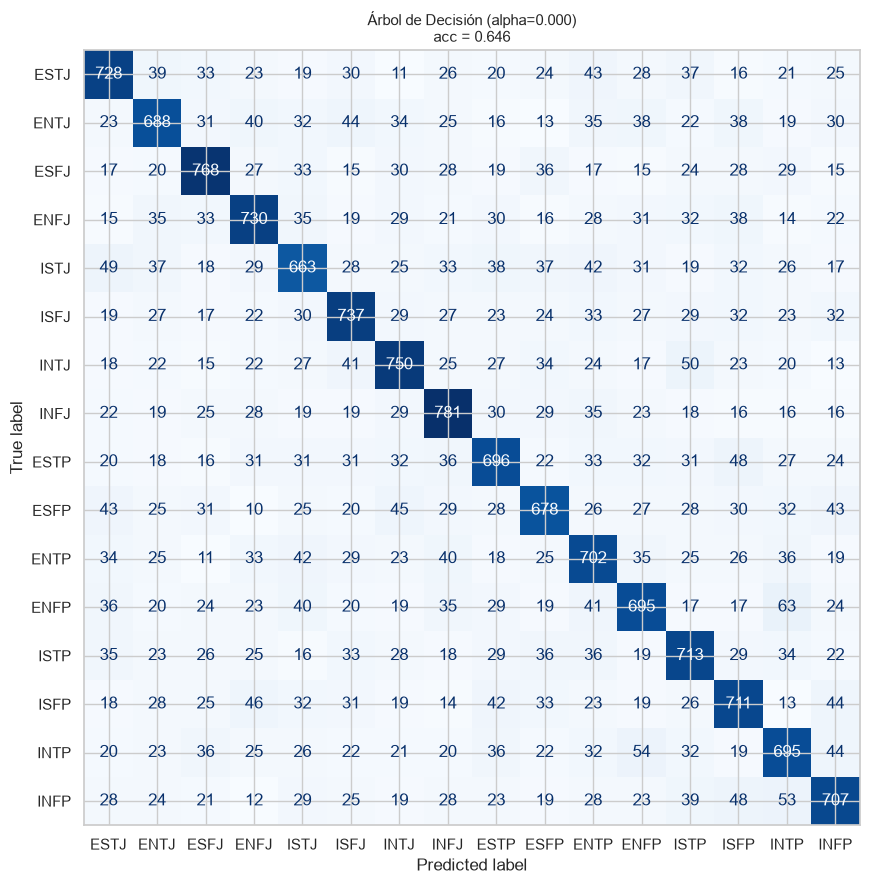

In [21]:
fig, ax = plt.subplots(figsize=(13, 9))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_sp, 
    display_labels=class_names, 
    cmap="Blues", 
    values_format="d", 
    ax=ax, 
    colorbar=False
)
ax.set_title(f"Árbol de Decisión (alpha={best_alpha:.3f})\nacc = {acc_ap:.3f}", fontsize=11)
plt.tight_layout()
plt.show()

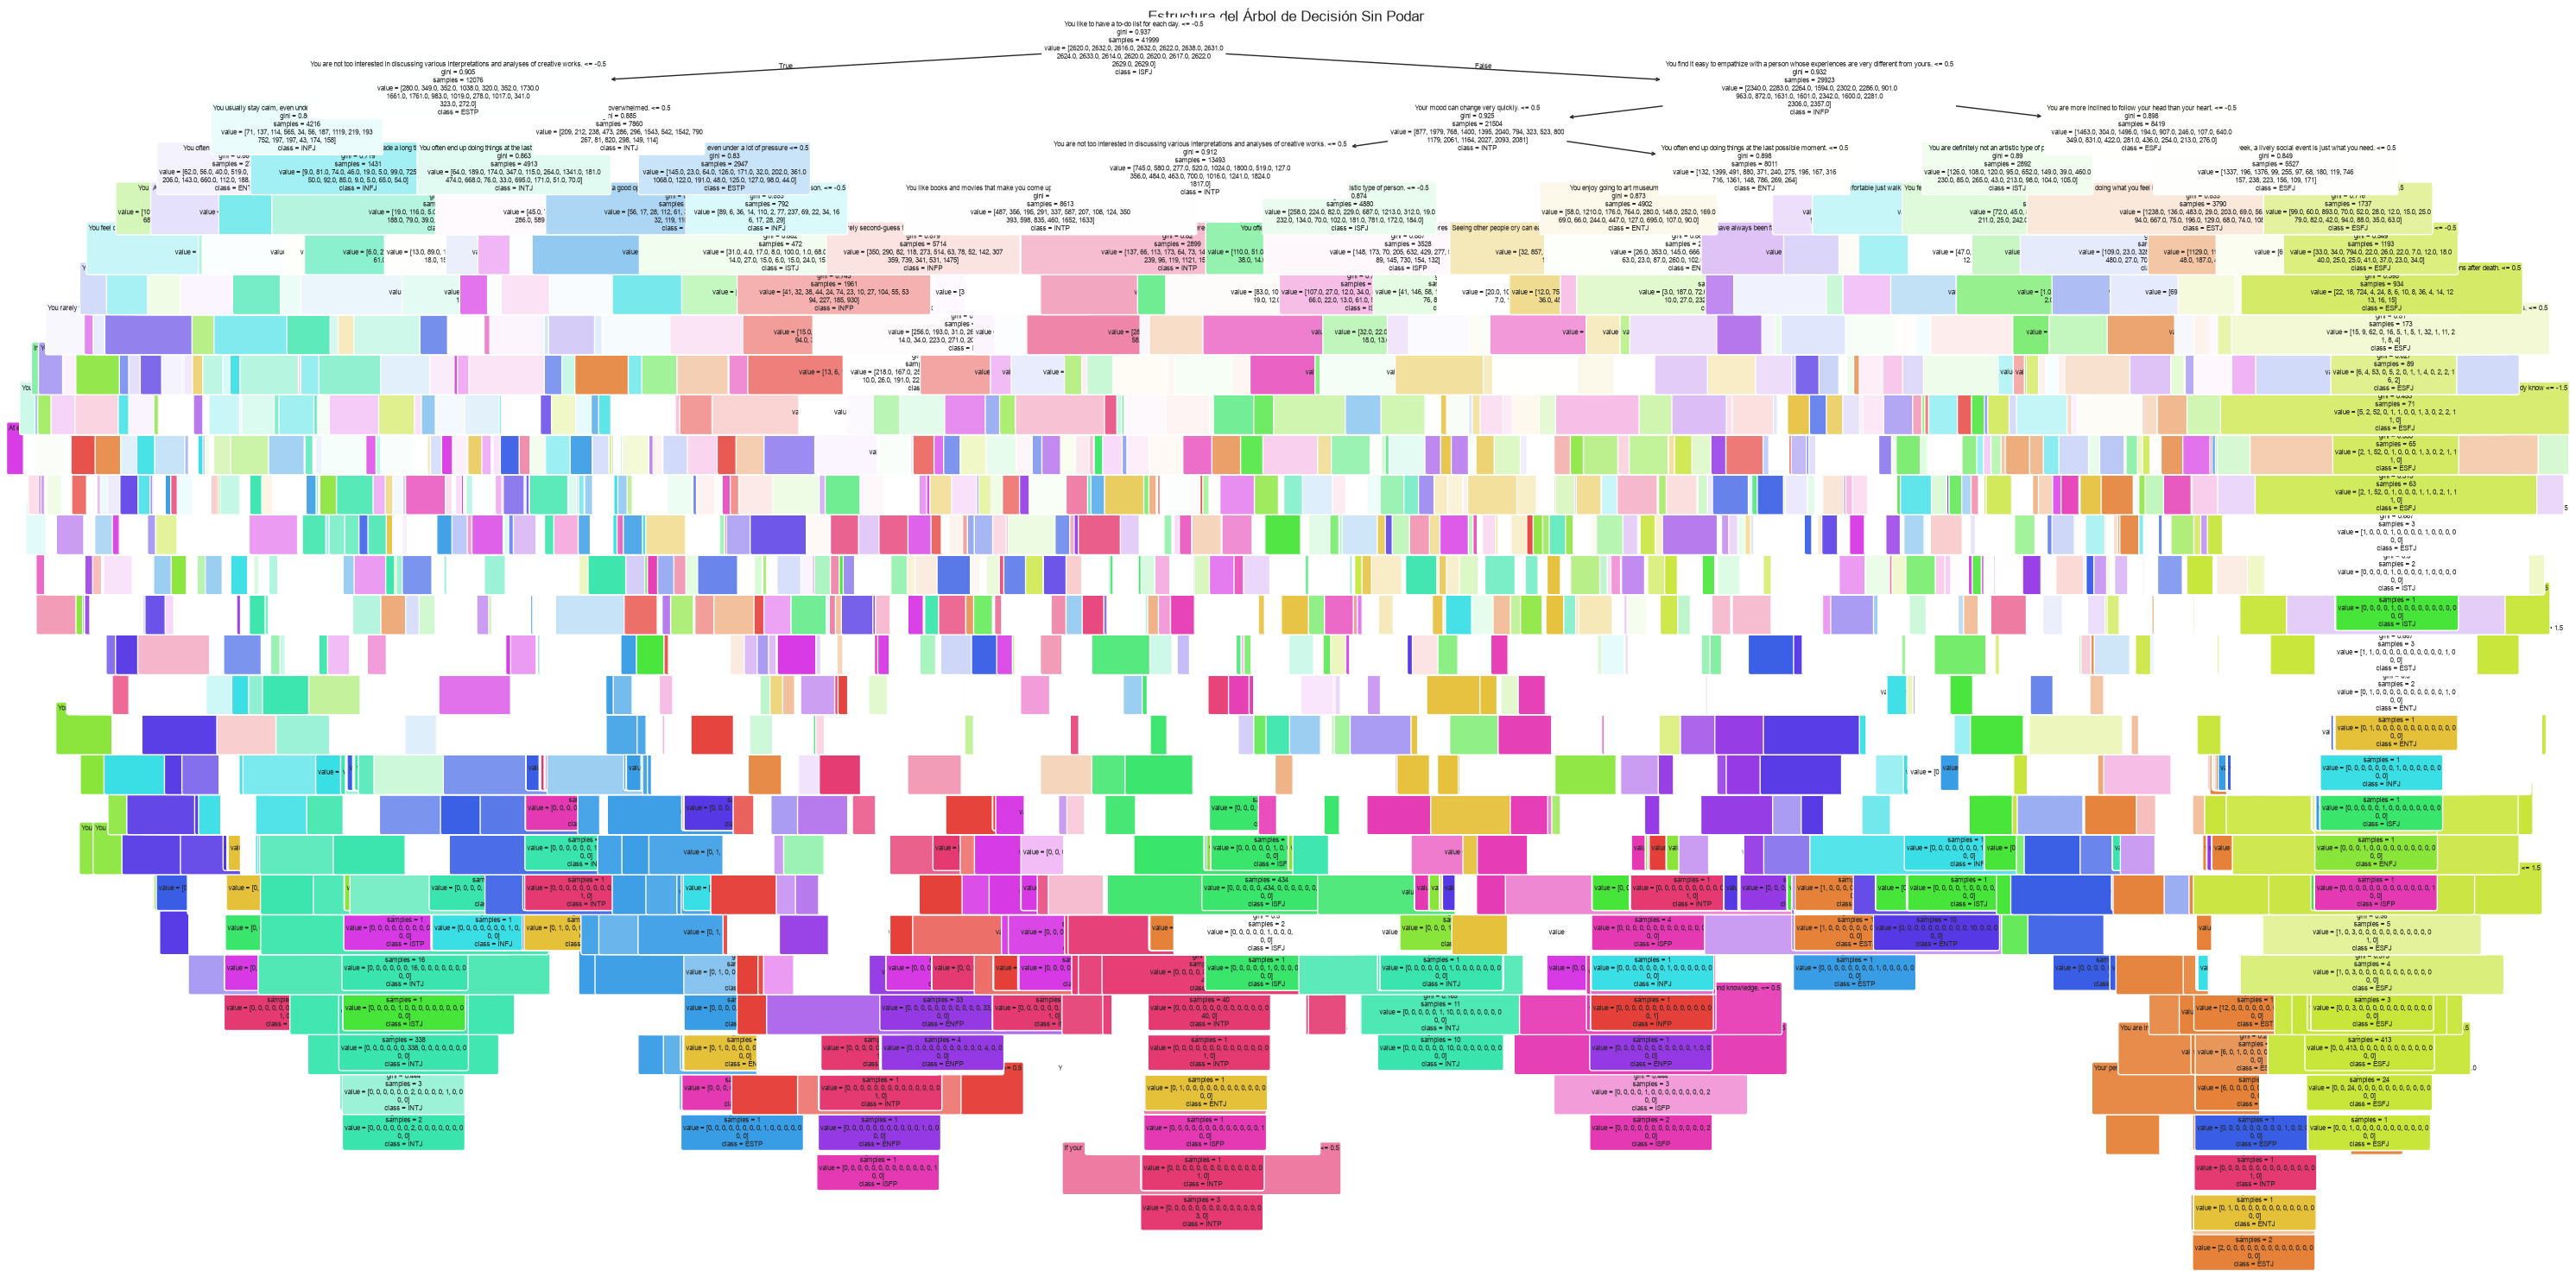

In [23]:
plt.figure(figsize=(30, 15))
plot_tree(
    arbol_sin_podar, 
    feature_names=X.columns, 
    class_names=class_names, 
    filled=True, 
    rounded=True, 
    fontsize=6
)
plt.title("Estructura del Árbol de Decisión Sin Podar", fontsize=12)
plt.tight_layout()
plt.show()